<a href="https://colab.research.google.com/github/Mohammedalirubel/GitHub/blob/main/predictive_analytics_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Analytics: Class Demo
### Stock Price Prediction (LSTM) · Sales Forecasting · Waiter Tips Regression · Deployment

This notebook walks through all four parts of the project:
1. Stock price prediction using an LSTM neural network
2. Sales forecasting and time-series analysis
3. Waiter tips prediction and regression refinement
4. Deploying a prediction pipeline

All data here is **synthetic**, generated for teaching purposes.

In [1]:
!pip install -q bdshare

from datetime import date
from functools import lru_cache
from io import StringIO
import re

import pandas as pd
from bdshare import get_historical_data
from fastapi import FastAPI, HTTPException, Query
from fastapi.responses import StreamingResponse

app = FastAPI(title='DSE Historical Data API', version='1.1.0')
COLUMNS = ['DATE', 'TRADING CODE', 'LTP*', 'HIGH', 'LOW', 'OPENP*', 'CLOSEP*', 'YCP', 'TRADE', 'VALUE (mn)', 'VOLUME']
ALIASES = {
    'date': 'DATE', 'tradingcode': 'TRADING CODE', 'symbol': 'TRADING CODE', 'code': 'TRADING CODE',
    'ltp': 'LTP*', 'high': 'HIGH', 'low': 'LOW', 'openp': 'OPENP*', 'open': 'OPENP*',
    'closep': 'CLOSEP*', 'close': 'CLOSEP*', 'ycp': 'YCP', 'trade': 'TRADE',
    'value': 'VALUE (mn)', 'valuemn': 'VALUE (mn)', 'volume': 'VOLUME'
}

def normalize(raw: pd.DataFrame) -> pd.DataFrame:
    if raw is None or raw.empty:
        return pd.DataFrame(columns=COLUMNS)
    df = raw.reset_index().copy()
    df.columns = [ALIASES.get(re.sub(r'[^a-z0-9]', '', str(c).lower()), str(c)) for c in df.columns]
    df = df.loc[:, ~df.columns.duplicated()]
    required = {'DATE', 'TRADING CODE', 'CLOSEP*'}
    if not required.issubset(df.columns):
        raise ValueError(f'Unexpected DSE response columns: {list(df.columns)}')
    for col in COLUMNS:
        if col not in df.columns:
            df[col] = None
    df['DATE'] = pd.to_datetime(df['DATE'], errors='coerce').dt.strftime('%Y-%m-%d')
    df['TRADING CODE'] = df['TRADING CODE'].astype(str).str.upper().str.strip()
    for col in COLUMNS[2:]:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=False), errors='coerce')
    df = df.dropna(subset=['DATE']).drop_duplicates(subset=['DATE', 'TRADING CODE'])
    return df[COLUMNS].sort_values(['DATE', 'TRADING CODE']).reset_index(drop=True)

@lru_cache(maxsize=32)
def fetch(start: str, end: str, code: str) -> pd.DataFrame:
    # Empty code requests all instruments. The library handles new/legacy DSE sources.
    raw = get_historical_data(start, end, code or None)
    return normalize(raw)

def get_data(start_date: date, end_date: date, trading_code: str | None):
    if start_date > end_date:
        raise HTTPException(400, 'start_date must not be after end_date')
    code = (trading_code or '').strip().upper()
    try:
        df = fetch(start_date.isoformat(), end_date.isoformat(), code).copy()
    except Exception as exc:
        raise HTTPException(502, f'DSE upstream retrieval failed: {exc}') from exc
    if code:
        df = df[df['TRADING CODE'] == code]
    return df

@app.get('/api/dse/data')
def data(start_date: date = date(2025, 4, 14), end_date: date = date(2026, 10, 11),
         trading_code: str | None = None, limit: int | None = Query(None, ge=1),
         offset: int = Query(0, ge=0)):
    df = get_data(start_date, end_date, trading_code)
    selected = df.iloc[offset:] if limit is None else df.iloc[offset:offset + limit]
    page = selected.astype(object).where(pd.notna(selected), None)
    return {'total': len(df), 'offset': offset, 'limit': limit, 'returned': len(page), 'columns': COLUMNS,
            'data': page.to_dict(orient='records')}

@app.get('/api/dse/codes')
def codes(start_date: date = date(2025, 4, 14), end_date: date = date(2026, 10, 11)):
    df = get_data(start_date, end_date, None)
    return {'count': df['TRADING CODE'].nunique(), 'codes': sorted(df['TRADING CODE'].unique().tolist())}

@app.get('/api/dse/download')
def download(start_date: date = date(2025, 4, 14), end_date: date = date(2026, 10, 11),
             trading_code: str | None = None):
    df = get_data(start_date, end_date, trading_code)
    output = StringIO()
    df.to_csv(output, index=False)
    return StreamingResponse(iter([output.getvalue()]), media_type='text/csv',
        headers={'Content-Disposition': 'attachment; filename="dse_historical_data.csv"'})

In [2]:
import nest_asyncio
import uvicorn
import threading
import requests
import time
import socket

nest_asyncio.apply()

# ============================================================
# 1. FIND AN AVAILABLE PORT
# ============================================================

def find_free_port(start_port=8000):
    for port in range(start_port, start_port + 100):
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            try:
                s.bind(("127.0.0.1", port))
                return port
            except OSError:
                continue
    raise RuntimeError("No available port found")

PORT = find_free_port()

# ============================================================
# 2. START FASTAPI SERVER
# ============================================================

config = uvicorn.Config(
    app,
    host="127.0.0.1",
    port=PORT,
    log_level="warning"
)

server = uvicorn.Server(config)

api_thread = threading.Thread(
    target=server.run,
    daemon=True
)

api_thread.start()

# ============================================================
# 3. VERIFY SERVER STATUS
# ============================================================

base_url = f"http://127.0.0.1:{PORT}"

server_running = False

for _ in range(20):
    if not api_thread.is_alive():
        break

    try:
        response = requests.get(
            f"{base_url}/openapi.json",
            timeout=1
        )

        if response.status_code == 200:
            server_running = True
            break

    except requests.RequestException:
        pass

    time.sleep(0.5)

if server_running:
    print("=" * 50)
    print("FASTAPI SERVER STARTED SUCCESSFULLY")
    print("=" * 50)
    print("Server:", base_url)
    print("API Documentation:", f"{base_url}/docs")
else:
    print("FastAPI server failed to start.")

FASTAPI SERVER STARTED SUCCESSFULLY
Server: http://127.0.0.1:8000
API Documentation: http://127.0.0.1:8000/docs


In [3]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8000/openapi.json",
        timeout=5
    )

    if response.status_code == 200:
        print("FastAPI is already running on port 8000")
        print("API routes:")
        for path in response.json().get("paths", {}):
            print(path)
    else:
        print("Port 8000 responds, but FastAPI was not confirmed.")

except requests.RequestException as e:
    print("Could not connect:", e)

FastAPI is already running on port 8000
API routes:
/api/dse/data
/api/dse/codes
/api/dse/download


In [ ]:
server.should_exit = True
api_thread.join(timeout=5)

In [4]:
import requests

for port in [8000, 8001, 8002, 8003, 8004]:
    try:
        response = requests.get(
            f"http://127.0.0.1:{port}/openapi.json",
            timeout=2
        )
        if response.status_code == 200:
            print(f"FastAPI running on port {port}")
            print("API URL:", f"http://127.0.0.1:{port}")
        else:
            print(f"Port {port}: HTTP {response.status_code}")
    except requests.RequestException:
        print(f"Port {port}: No API connection")

FastAPI running on port 8000
API URL: http://127.0.0.1:8000
Port 8001: No API connection
Port 8002: No API connection
Port 8003: No API connection
Port 8004: No API connection


In [5]:
import nest_asyncio
import uvicorn
import threading
import requests
import socket
import time

nest_asyncio.apply()

# Confirm FastAPI app exists
if "app" not in globals():
    raise RuntimeError(
        "FastAPI app not defined. Run the cell containing "
        "app = FastAPI() and your API routes first."
    )

# Find an available port
def get_free_port():
    with socket.socket() as sock:
        sock.bind(("127.0.0.1", 0))
        return sock.getsockname()[1]

PORT = get_free_port()

# Configure server
config = uvicorn.Config(
    app=app,
    host="127.0.0.1",
    port=PORT,
    log_level="info"
)

server = uvicorn.Server(config)

api_thread = threading.Thread(
    target=server.run,
    daemon=True
)

api_thread.start()

BASE_URL = f"http://127.0.0.1:{PORT}"

# Wait for successful startup
connected = False

for attempt in range(30):
    if not api_thread.is_alive():
        break

    try:
        response = requests.get(
            f"{BASE_URL}/openapi.json",
            timeout=2
        )
        if response.status_code == 200:
            connected = True
            break
    except requests.RequestException:
        pass

    time.sleep(0.5)

if connected:
    print("FastAPI started successfully")
    print("API URL:", BASE_URL)
    print("Documentation:", BASE_URL + "/docs")
else:
    raise RuntimeError(
        "FastAPI failed to start. Check the server logs above."
    )

INFO:     Started server process [140266]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:38881 (Press CTRL+C to quit)


INFO:     127.0.0.1:42876 - "GET /openapi.json HTTP/1.1" 200 OK
FastAPI started successfully
API URL: http://127.0.0.1:38881
Documentation: http://127.0.0.1:38881/docs


In [6]:
from datetime import datetime, timedelta
from bdshare import get_historical_data

# Calculate a larger 150-day window to ensure sufficient historical data for the LSTM models
end_date_str = (datetime.now() - timedelta(days=1)).strftime('%Y-%m-%d')
start_date_str = (datetime.now() - timedelta(days=150)).strftime('%Y-%m-%d')

try:
    print(f"Fetching historical data from {start_date_str} to {end_date_str}...")
    # Fetch data for all instruments
    raw_df = get_historical_data(start_date_str, end_date_str)
    df = normalize(raw_df)
    print(f"Successfully downloaded data! Shape: {df.shape}")
    display(df.head())
except Exception as e:
    print("Error retrieving data directly:", e)

Fetching historical data from 2026-05-16 to 2026-10-12...
Successfully downloaded data! Shape: (63808, 11)


,DATE,TRADING CODE,LTP*,HIGH,LOW,OPENP*,CLOSEP*,YCP,TRADE,VALUE (mn),VOLUME
0,2026-05-17,1JANATAMF,3.0,3.1,3.0,3.1,3.0,3.0,176,2.849,948101
1,2026-05-17,1STPRIMFMF,18.6,19.0,18.4,19.0,18.6,18.8,264,4.578,246489
2,2026-05-17,AAMRANET,16.3,16.3,16.1,16.2,16.2,16.1,122,1.733,107244
3,2026-05-17,AAMRATECH,13.0,13.7,12.7,13.7,13.0,12.6,163,1.803,139545
4,2026-05-17,ABB1STMF,3.2,3.3,3.1,3.2,3.2,3.2,165,3.893,1217969


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63808 entries, 0 to 63807
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   DATE          63808 non-null  object 
 1   TRADING CODE  63808 non-null  object 
 2   LTP*          63808 non-null  float64
 3   HIGH          63808 non-null  float64
 4   LOW           63808 non-null  float64
 5   OPENP*        63808 non-null  float64
 6   CLOSEP*       63808 non-null  float64
 7   YCP           63808 non-null  float64
 8   TRADE         63808 non-null  int64  
 9   VALUE (mn)    63808 non-null  float64
 10  VOLUME        63808 non-null  int64  
dtypes: float64(7), int64(2), object(2)
memory usage: 5.4+ MB


In [9]:
df['TRADING CODE']

,TRADING CODE
0,1JANATAMF
1,1STPRIMFMF
2,AAMRANET
3,AAMRATECH
4,ABB1STMF
...,...
63803,WMSHIPYARD
63804,YPL
63805,ZAHEENSPIN
63806,ZAHINTEX


In [10]:

import pandas as pd

df['TRADING CODE'] = df['TRADING CODE'].astype(str).str.strip().str.upper()

# Common non-equity trading code patterns
exclude_patterns = (
    r'MF$|MUTUAL|BOND|DEB|TB\d|TNOTE|TBill'
)

df_shares = df[
    ~df['TRADING CODE'].str.contains(
        exclude_patterns,
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Original trading codes:", df['TRADING CODE'].nunique())
print("Remaining trading codes:", df_shares['TRADING CODE'].nunique())
print("Removed trading codes:",
      df['TRADING CODE'].nunique() -
      df_shares['TRADING CODE'].nunique())

display(df_shares.head())


Original trading codes: 644
Remaining trading codes: 380
Removed trading codes: 264


,DATE,TRADING CODE,LTP*,HIGH,LOW,OPENP*,CLOSEP*,YCP,TRADE,VALUE (mn),VOLUME
2,2026-05-17,AAMRANET,16.3,16.3,16.1,16.2,16.2,16.1,122,1.733,107244
3,2026-05-17,AAMRATECH,13.0,13.7,12.7,13.7,13.0,12.6,163,1.803,139545
5,2026-05-17,ABBANK,4.3,4.5,4.3,4.5,4.3,4.4,115,1.453,333952
7,2026-05-17,ACFL,19.6,19.9,19.4,19.8,19.6,19.5,163,2.917,148200
8,2026-05-17,ACI,188.6,190.8,188.0,190.4,188.8,190.4,251,2.633,13923


In [11]:
print("Available Columns:", df.columns.tolist())

# Since 'INSTRUMENT TYPE' is missing, filter using patterns in 'TRADING CODE'
df['TRADING CODE'] = df['TRADING CODE'].astype(str).str.strip().str.upper()

# Common non-equity patterns (Mutual Funds, Bonds, Debentures, Treasuries)
exclude_patterns = r'MF$|MUTUAL|BOND|DEB|TB\d|TNOTE|TBill'

df_shares = df[
    ~df['TRADING CODE'].str.contains(
        exclude_patterns,
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Original unique codes:", df['TRADING CODE'].nunique())
print("Unique equity trading codes:", df_shares['TRADING CODE'].nunique())

Available Columns: ['DATE', 'TRADING CODE', 'LTP*', 'HIGH', 'LOW', 'OPENP*', 'CLOSEP*', 'YCP', 'TRADE', 'VALUE (mn)', 'VOLUME']
Original unique codes: 644
Unique equity trading codes: 380


In [12]:
import pandas as pd

# Convert DATE column to datetime
df['DATE'] = pd.to_datetime(df['DATE'], errors='coerce')

# Sort by DATE and TRADING CODE
df = df.sort_values(
    by=['TRADING CODE', 'DATE']
).reset_index(drop=True)

# Check updated data types
df.info()

# Display first 5 rows
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63808 entries, 0 to 63807
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   DATE          63808 non-null  datetime64[ns]
 1   TRADING CODE  63808 non-null  object        
 2   LTP*          63808 non-null  float64       
 3   HIGH          63808 non-null  float64       
 4   LOW           63808 non-null  float64       
 5   OPENP*        63808 non-null  float64       
 6   CLOSEP*       63808 non-null  float64       
 7   YCP           63808 non-null  float64       
 8   TRADE         63808 non-null  int64         
 9   VALUE (mn)    63808 non-null  float64       
 10  VOLUME        63808 non-null  int64         
dtypes: datetime64[ns](1), float64(7), int64(2), object(1)
memory usage: 5.4+ MB


,DATE,TRADING CODE,LTP*,HIGH,LOW,OPENP*,CLOSEP*,YCP,TRADE,VALUE (mn),VOLUME
0,2026-05-17,1JANATAMF,3.0,3.1,3.0,3.1,3.0,3.0,176,2.849,948101
1,2026-05-18,1JANATAMF,2.9,3.1,2.9,3.0,2.9,3.0,158,3.710,1265303
2,2026-05-19,1JANATAMF,3.0,3.0,2.9,3.0,3.0,2.9,61,0.645,220187
3,2026-05-20,1JANATAMF,2.9,3.0,2.9,3.0,2.9,3.0,145,1.165,400016
4,2026-05-21,1JANATAMF,3.0,3.0,2.9,2.9,3.0,2.9,126,1.130,381846


In [ ]:

import pandas as pd

df['TRADING CODE'] = df['TRADING CODE'].astype(str).str.strip().str.upper()

# Common non-equity trading code patterns
exclude_patterns = (
    r'MF$|MUTUAL|BOND|DEB|TB\d|TNOTE|TBill'
)

df_shares = df[
    ~df['TRADING CODE'].str.contains(
        exclude_patterns,
        case=False,
        regex=True,
        na=False
    )
].copy()

print("Original trading codes:", df['TRADING CODE'].nunique())
print("Remaining trading codes:", df_shares['TRADING CODE'].nunique())
print("Removed trading codes:",
      df['TRADING CODE'].nunique() -
      df_shares['TRADING CODE'].nunique())

display(df_shares.head())


Original trading codes: 644
Remaining trading codes: 380
Removed trading codes: 264


,DATE,TRADING CODE,LTP*,HIGH,LOW,OPENP*,CLOSEP*,YCP,TRADE,VALUE (mn),VOLUME
200,2026-05-17,AAMRANET,16.3,16.3,16.1,16.2,16.2,16.1,122,1.733,107244
201,2026-05-18,AAMRANET,16.4,16.6,16.4,16.5,16.4,16.2,302,3.572,216837
202,2026-05-19,AAMRANET,16.2,16.5,16.1,16.3,16.2,16.4,126,1.836,113325
203,2026-05-20,AAMRANET,16.6,16.6,16.1,16.1,16.4,16.2,166,2.305,140971
204,2026-05-21,AAMRANET,16.6,16.7,16.4,16.7,16.6,16.4,147,2.138,129132


In [13]:
df = df_shares.copy()

trading_codes = sorted(df['TRADING CODE'].unique())

print("Total shares available for LSTM training:", len(trading_codes))

Total shares available for LSTM training: 380


## Part 1 — Stock Price Prediction Using an LSTM Neural Network

An LSTM (Long Short-Term Memory) network is a type of recurrent neural network well suited to sequences, such as a stock's daily closing price. We will:
1. Take one ticker's closing prices
2. Scale them to [0, 1]
3. Build sliding windows (use the past 20 days to predict the next day)
4. Train a small LSTM and evaluate it on unseen, later dates

In [23]:
import ipywidgets as widgets
from IPython.display import display
import matplotlib.pyplot as plt

# Get all trading codes
trading_codes = sorted(
    df['TRADING CODE'].dropna().unique()
)

dropdown = widgets.Dropdown(
    options=trading_codes,
    value='BRACBANK' if 'BRACBANK' in trading_codes else trading_codes[0],
    description='Trading Code:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='350px')
)

def plot_stock(trading_code):
    data = df[
        df['TRADING CODE'] == trading_code
    ].copy()

    data['DATE'] = pd.to_datetime(data['DATE'])
    data = data.sort_values('DATE')

    plt.figure(figsize=(12, 4))
    plt.plot(
        data['DATE'],
        data['CLOSEP*'],
        color='#0E7C86'
    )

    plt.title(f'{trading_code} Closing Price')
    plt.xlabel('Date')
    plt.ylabel('Price (BDT)')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

widgets.interact(
    plot_stock,
    trading_code=dropdown
)

interactive(children=(Dropdown(description='Trading Code:', index=69, layout=Layout(width='350px'), options=('…

<function __main__.plot_stock(trading_code)>

In [24]:
# Exclude mutual funds from online stock predictor
EXCLUDED_CODES = {
    "1JANATAMF", "1STPRIMFMF", "AIBL1STIMF",
    "ATCSLGF", "CAPMBDBLMF", "CAPMIBBLMF",
    "DBH1STMF", "EBL1STMF", "EBLNRBMF",
    "EXIM1STMF", "FBFIF", "IC3RDNRB",
    "ICBAGRANI1", "ICBAMCL2ND", "ICBEPMF1S1",
    "ICBSONALI1", "IFILISLMF1", "LANKABA1MF",
    "LRGLOBMF1", "MBL1STMF", "NCCBLMF1",
    "NLI1STMF", "PHPMF1", "POPULAR1MF",
    "PRIME1ICBA", "RELIANCE1", "SEMLIBBLSF",
    "SEMLLECMF", "TRUSTB1MF", "VAMLBDG1",
    "VAMLRBBF,1JANATAMF", "1STPRIMFMF", "AIBL1STIMF",
    "ATCSLGF", "CAPMBDBLMF", "CAPMIBBLMF",
    "DBH1STMF", "EBL1STMF", "EBLNRBMF",
    "EXIM1STMF", "FBFIF", "IC3RDNRB",
    "ICBAGRANI1", "ICBAMCL2ND", "ICBEPMF1S1",
    "ICBSONALI1", "IFILISLMF1", "LANKABA1MF",
    "LRGLOBMF1", "MBL1STMF", "NCCBLMF1",
    "NLI1STMF", "PHPMF1", "POPULAR1MF",
    "PRIME1ICBA", "RELIANCE1", "SEMLIBBLSF",
    "SEMLLECMF", "TRUSTB1MF", "VAMLBDG1",
    "VAMLRBBF "
}

# Using 'df' instead of 'stock_df' and matching column name 'TRADING CODE'
df = df[
    ~df["TRADING CODE"]
    .astype(str)
    .str.strip()
    .str.upper()
    .isin(EXCLUDED_CODES)
].copy()


In [25]:

trading_codes = sorted(
    code for code in trading_codes
    if str(code).strip().upper() not in EXCLUDED_CODES
)


In [26]:
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler

tf.random.set_seed(42)
np.random.seed(42)

# ============================================================
# CONFIGURATION
# ============================================================

WINDOW = 20
TRAIN_RATIO = 0.80

# ============================================================
# PREPARE DSE DATA
# ============================================================

stock = df.copy()

stock['DATE'] = pd.to_datetime(
    stock['DATE'],
    errors='coerce'
)

stock['CLOSEP*'] = pd.to_numeric(
    stock['CLOSEP*'],
    errors='coerce'
)

stock = stock.dropna(
    subset=['DATE', 'TRADING CODE', 'CLOSEP*']
)

stock = stock.sort_values(
    ['TRADING CODE', 'DATE']
).reset_index(drop=True)

# ============================================================
# STORAGE FOR ALL TRADING CODES
# ============================================================

stock_datasets = {}
stock_scalers = {}
skipped_codes = []

trading_codes = sorted(
    stock['TRADING CODE'].unique()
)

# ============================================================
# PREPARE EACH TRADING CODE
# ============================================================

for code in trading_codes:

    data = stock[
        stock['TRADING CODE'] == code
    ].sort_values('DATE').reset_index(drop=True)

    prices = data['CLOSEP*'].values.reshape(-1, 1)

    # Require enough observations for training and testing
    if len(prices) < WINDOW + 10:
        skipped_codes.append(code)
        continue

    # Time-based split on original price series
    train_size = int(len(prices) * TRAIN_RATIO)

    if train_size <= WINDOW or len(prices) - train_size < 1:
        skipped_codes.append(code)
        continue

    # Fit scaler ONLY on training data
    scaler = MinMaxScaler()
    scaler.fit(prices[:train_size])

    scaled = scaler.transform(prices)

    # Create sequences
    X, y = [], []
    target_indices = []

    for i in range(WINDOW, len(scaled)):
        X.append(scaled[i-WINDOW:i, 0])
        y.append(scaled[i, 0])
        target_indices.append(i)

    X = np.array(X, dtype=np.float32)
    y = np.array(y, dtype=np.float32)
    target_indices = np.array(target_indices)

    X = X.reshape(X.shape[0], WINDOW, 1)

    # Split based on target date, not shuffled samples
    train_mask = target_indices < train_size
    test_mask = target_indices >= train_size

    X_train = X[train_mask]
    X_test = X[test_mask]

    y_train = y[train_mask]
    y_test = y[test_mask]

    # Store prepared datasets
    stock_datasets[code] = {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'dates': data['DATE'].values,
        'prices': prices,
        'last_close': float(prices[-1, 0]),
        'last_date': data['DATE'].iloc[-1]
    }

    stock_scalers[code] = scaler

# ============================================================
# SUMMARY
# ============================================================

print("=" * 55)
print("DSE STOCK DATA PREPARATION COMPLETED")
print("=" * 55)

print("Total Trading Codes:", len(trading_codes))
print("Prepared Codes:", len(stock_datasets))
print("Skipped Codes:", len(skipped_codes))

print("\nSample Training Shapes:")

for code in list(stock_datasets.keys())[:10]:
    d = stock_datasets[code]
    print(
        f"{code:15} "
        f"Train: {d['X_train'].shape} "
        f"Test: {d['X_test'].shape}"
    )

DSE STOCK DATA PREPARATION COMPLETED
Total Trading Codes: 368
Prepared Codes: 367
Skipped Codes: 1

Sample Training Shapes:
AAMRANET        Train: (60, 20, 1) Test: (20, 20, 1)
AAMRATECH       Train: (60, 20, 1) Test: (20, 20, 1)
ABBANK          Train: (60, 20, 1) Test: (20, 20, 1)
ACFL            Train: (60, 20, 1) Test: (20, 20, 1)
ACI             Train: (60, 20, 1) Test: (20, 20, 1)
ACIFORMULA      Train: (60, 20, 1) Test: (20, 20, 1)
ACMELAB         Train: (60, 20, 1) Test: (20, 20, 1)
ACMEPL          Train: (60, 20, 1) Test: (20, 20, 1)
ACTIVEFINE      Train: (60, 20, 1) Test: (20, 20, 1)
ADNTEL          Train: (60, 20, 1) Test: (20, 20, 1)


In [27]:
from tensorflow import keras

model = keras.Sequential([
    keras.layers.Input(shape=(WINDOW, 1)),
    keras.layers.LSTM(32, return_sequences=False),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1),
])
model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_49"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_49 (LSTM)                  │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_98 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_99 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Store models and training histories
stock_models = {}
stock_histories = {}
training_summary = []

EPOCHS = 15
BATCH_SIZE = 16

for i, (code, data) in enumerate(stock_datasets.items(), 1):

    X_train = data['X_train']
    y_train = data['y_train']

    # Skip stocks with insufficient training observations
    if len(X_train) < 10:
        print(f"Skipping {code}: insufficient data")
        continue

    print(f"Training {i}/{len(stock_datasets)}: {code}")

    # Create a new model for each trading code
    model = Sequential([
        Input(shape=(WINDOW, 1)),
        LSTM(32),
        Dense(16, activation='relu'),
        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse'
    )

    # Reserve the latest portion of training data
    # for validation; keep test data untouched
    history = model.fit(
        X_train,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.2,
        shuffle=False,
        verbose=0
    )

    stock_models[code] = model
    stock_histories[code] = history.history

    training_summary.append({
        'TRADING CODE': code,
        'TRAIN LOSS': history.history['loss'][-1],
        'VALIDATION LOSS': history.history['val_loss'][-1],
        'EPOCHS': len(history.history['loss'])
    })

print("\nAll eligible trading codes trained.")

training_summary_df = pd.DataFrame(training_summary)

display(training_summary_df)

Training 1/367: AAMRANET
Training 2/367: AAMRATECH
Training 3/367: ABBANK
Training 4/367: ACFL
Training 5/367: ACI
Training 6/367: ACIFORMULA
Training 7/367: ACMELAB
Training 8/367: ACMEPL
Training 9/367: ACTIVEFINE
Training 10/367: ADNTEL
Training 11/367: ADVENT
Training 12/367: AFCAGRO
Training 13/367: AFTABAUTO
Training 14/367: AGNISYSL
Training 15/367: AGRANINS
Training 16/367: AIL
Training 17/367: AL-HAJTEX
Training 18/367: ALARABANK
Training 19/367: ALIF
Training 20/367: ALLTEX
Training 21/367: AMANFEED
Training 22/367: AMBEEPHA
Training 23/367: AMCL(PRAN)
Training 24/367: ANLIMAYARN
Training 25/367: ANWARGALV
Training 26/367: AOL
Training 27/367: APEXFOODS
Training 28/367: APEXFOOT
Training 29/367: APEXSPINN
Training 30/367: APEXTANRY
Training 31/367: APOLOISPAT
Training 32/367: ARAMIT
Training 33/367: ARAMITCEM
Training 34/367: ARGONDENIM
Training 35/367: ASIAINS
Training 36/367: ASIAPACINS
Training 37/367: ASIATICLAB
Training 38/367: ATLASBANG
Training 39/367: AZIZPIPES
Traini

,TRADING CODE,TRAIN LOSS,VALIDATION LOSS,EPOCHS
0,AAMRANET,0.012348,0.071494,15
1,AAMRATECH,0.024484,0.031185,15
2,ABBANK,0.018404,0.054206,15
3,ACFL,0.015534,0.020991,15
4,ACI,0.019460,0.043928,15
...,...,...,...,...
362,WMSHIPYARD,0.048998,0.274340,15
363,YPL,0.008343,0.054593,15
364,ZAHEENSPIN,0.019266,0.027683,15
365,ZAHINTEX,0.025058,0.072188,15


### Visualizing LSTM Training History
Use the dropdown below to select any stock ticker and display its training and validation loss curves over the 15 epochs.

In [29]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

# Get the list of stocks with available training histories
available_histories = sorted(list(stock_histories.keys()))

if not available_histories:
    print("No training histories found. Please ensure the LSTM model training cell has completed successfully.")
else:
    history_dropdown = widgets.Dropdown(
        options=available_histories,
        value='BRACBANK' if 'BRACBANK' in available_histories else available_histories[0],
        description='Select Stock:',
        style={'description_width': 'initial'},
        layout=widgets.Layout(width='350px')
    )

    def plot_history(ticker):
        history = stock_histories[ticker]

        plt.figure(figsize=(10, 5))
        plt.plot(history['loss'], label='Training Loss (MSE)', color='#0E7C86', linewidth=2)
        if 'val_loss' in history:
            plt.plot(history['val_loss'], label='Validation Loss (MSE)', color='#F29F05', linewidth=2, linestyle='--')

        plt.title(f'LSTM Training Loss Curves: {ticker}')
        plt.xlabel('Epoch')
        plt.ylabel('Loss (Mean Squared Error)')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.legend()
        plt.tight_layout()
        plt.show()

    widgets.interact(plot_history, ticker=history_dropdown)

interactive(children=(Dropdown(description='Select Stock:', index=68, layout=Layout(width='350px'), options=('…

Unified LSTM training code

**Discussion:** the LSTM only ever sees the past 20 days when it predicts the next day, and it is trained only on data *before* the test period — this is important, since shuffling a time series before splitting would let the model "see the future" and give an unrealistically good score.

Evaluate all trained models

In [33]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

performance_records = []

for code, dataset in stock_datasets.items():
    if code not in stock_models:
        continue

    model = stock_models[code]
    scaler = stock_scalers[code]

    X_test = dataset['X_test']
    y_test = dataset['y_test']
    prices = dataset['prices']
    train_size = int(len(prices) * TRAIN_RATIO)

    if len(X_test) == 0:
        continue

    # Generate predictions
    predictions_scaled = model.predict(X_test, verbose=0).flatten()

    # Inverse transform to original BDT scale
    predictions = scaler.inverse_transform(predictions_scaled.reshape(-1, 1)).flatten()
    actuals = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

    # Calculate Metrics
    mae = mean_absolute_error(actuals, predictions)
    rmse = np.sqrt(mean_squared_error(actuals, predictions))

    # Non-zero division safe MAPE
    nonzero = actuals != 0
    mape = np.mean(np.abs((actuals[nonzero] - predictions[nonzero]) / actuals[nonzero])) * 100 if nonzero.any() else np.nan

    r2 = r2_score(actuals, predictions) if len(actuals) > 1 else np.nan

    # Direction Accuracy
    # We compare the predicted direction (pred_t - actual_{t-1}) vs actual direction (actual_t - actual_{t-1})
    # For the first test element, t-1 is the last element of the training set
    last_train_price = prices[train_size - 1, 0]

    actual_prev = np.insert(actuals[:-1], 0, last_train_price)
    actual_dir = np.sign(actuals - actual_prev)
    pred_dir = np.sign(predictions - actual_prev)

    dir_acc = np.mean(actual_dir == pred_dir) * 100

    performance_records.append({
        'TRADING CODE': code,
        'MAE (BDT)': mae,
        'RMSE (BDT)': rmse,
        'MAPE (%)': mape,
        'R2 SCORE': r2,
        'DIRECTION ACCURACY (%)': dir_acc
    })

performance_df = pd.DataFrame(performance_records)
performance_df.to_csv("DSE_LSTM_Model_Performance.csv", index=False)
print(f"Evaluated {len(performance_df)} models and saved results to DSE_LSTM_Model_Performance.csv")

Evaluated 367 models and saved results to DSE_LSTM_Model_Performance.csv


In [34]:
import os
import pandas as pd

performance_csv = "DSE_LSTM_Model_Performance.csv"
if os.path.exists(performance_csv):
    performance_df = pd.read_csv(performance_csv)

if 'performance_df' not in globals() or performance_df.empty:
    print("No model evaluation records loaded. Please ensure cell 708e0a7c has run successfully first.")
else:
    print("=" * 55)
    print("DSE_LSTM MODEL PERFORMANCE SUMMARY (LOADED FROM DISK)")
    print("=" * 55)
    print("Total models evaluated:", len(performance_df))
    print("Average MAE (BDT):", round(performance_df["MAE (BDT)"].mean(), 3))
    print("Average RMSE (BDT):", round(performance_df["RMSE (BDT)"].mean(), 3))
    print("Average MAPE (%):", round(performance_df["MAPE (%)"].mean(), 2))
    print("Average R2:", round(performance_df["R2 SCORE"].mean(), 4))
    print("Average Direction Accuracy (%):", round(performance_df["DIRECTION ACCURACY (%)"].mean(), 2))

    print("\nTOP 20 MODELS BY MAPE")
    display(performance_df.sort_values("MAPE (%)").head(20))

DSE_LSTM MODEL PERFORMANCE SUMMARY (LOADED FROM DISK)
Total models evaluated: 367
Average MAE (BDT): 2.994
Average RMSE (BDT): 3.438
Average MAPE (%): 5.28
Average R2: -1039192546.7687
Average Direction Accuracy (%): 43.24

TOP 20 MODELS BY MAPE


,TRADING CODE,MAE (BDT),RMSE (BDT),MAPE (%),R2 SCORE,DIRECTION ACCURACY (%)
357,VAMLBDMF1,0.000000,0.000000,0.000000,1.000000,100.0
52,BDSERVICE,0.000000,0.000000,0.000000,1.000000,100.0
40,BANKASI1PB,0.000000,0.000000,0.000000,1.000000,100.0
310,SIBL,0.000000,0.000000,0.000000,1.000000,100.0
300,SAVAREFR,0.000000,0.000000,0.000000,1.000000,100.0
136,GIB,0.000000,0.000000,0.000000,1.000000,100.0
126,FIRSTSBANK,0.000000,0.000000,0.000000,1.000000,100.0
116,EXIMBANK,0.000000,0.000000,0.000000,1.000000,100.0
347,UNIONBANK,0.000000,0.000000,0.000000,1.000000,100.0
328,SQURPHARMA,0.942407,1.261927,0.436678,0.321202,55.0


In [36]:
import os
import pandas as pd

performance_csv = "DSE_LSTM_Model_Performance.csv"
if os.path.exists(performance_csv):
    performance_df = pd.read_csv(performance_csv)
else:
    performance_df = pd.DataFrame()

if performance_df.empty:
    print("No models evaluated. Please run the evaluation cell (708e0a7c) first to generate DSE_LSTM_Model_Performance.csv.")
else:
    print("=" * 55)
    print("DSE LSTM MODEL PERFORMANCE SUMMARY")
    print("=" * 55)

    print("Models evaluated:", len(performance_df))

    print(
        "Average MAE (BDT):",
        round(performance_df["MAE (BDT)"].mean(), 3)
    )

    print(
        "Average RMSE (BDT):",
        round(performance_df["RMSE (BDT)"].mean(), 3)
    )

    print(
        "Average MAPE (%):",
        round(performance_df["MAPE (%)"].mean(), 2)
    )

    print(
        "Average R2:",
        round(performance_df["R2 SCORE"].mean(), 4)
    )

    print(
        "Average Direction Accuracy (%):",
        round(
            performance_df["DIRECTION ACCURACY (%)"].mean(), 2
        )
    )

    print("\nTOP 20 MODELS BY MAPE")
    display(
        performance_df.sort_values("MAPE (%)").head(20)
    )

DSE LSTM MODEL PERFORMANCE SUMMARY
Models evaluated: 367
Average MAE (BDT): 2.994
Average RMSE (BDT): 3.438
Average MAPE (%): 5.28
Average R2: -1039192546.7687
Average Direction Accuracy (%): 43.24

TOP 20 MODELS BY MAPE


,TRADING CODE,MAE (BDT),RMSE (BDT),MAPE (%),R2 SCORE,DIRECTION ACCURACY (%)
357,VAMLBDMF1,0.000000,0.000000,0.000000,1.000000,100.0
52,BDSERVICE,0.000000,0.000000,0.000000,1.000000,100.0
40,BANKASI1PB,0.000000,0.000000,0.000000,1.000000,100.0
310,SIBL,0.000000,0.000000,0.000000,1.000000,100.0
300,SAVAREFR,0.000000,0.000000,0.000000,1.000000,100.0
136,GIB,0.000000,0.000000,0.000000,1.000000,100.0
126,FIRSTSBANK,0.000000,0.000000,0.000000,1.000000,100.0
116,EXIMBANK,0.000000,0.000000,0.000000,1.000000,100.0
347,UNIONBANK,0.000000,0.000000,0.000000,1.000000,100.0
328,SQURPHARMA,0.942407,1.261927,0.436678,0.321202,55.0


## Part 2 — Sales Forecasting and Time-Series Analysis

Next we forecast daily sales for one store, using classical time-series decomposition and Exponential Smoothing (Holt-Winters), which explicitly models trend and seasonality — a natural complement to the LSTM approach above.

**Discussion:** adding day, time, and party size on top of total_bill usually improves R² only modestly, since total_bill alone already captures most of the signal (larger bills mean larger tips). This is a useful, realistic result to discuss: refinement does not always produce a dramatically better model, and knowing *why* is part of the analysis.

In [40]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Safely initialize 'north' if not in memory
if 'north' not in globals():
    if 'daily_sales' in globals():
        north = daily_sales
    else:
        # Generate a synthetic daily sales series (366 days) matching the exercise structure
        np.random.seed(42)
        date_range = pd.date_range(start="2025-01-01", periods=366, freq="D")
        # Baseline sales with a weekly seasonality
        base_sales = 200 + 10 * np.sin(2 * np.pi * date_range.dayofweek / 7)
        noise = np.random.normal(0, 15, size=366)
        north = pd.Series(base_sales + noise, index=date_range, name="sales")

# Split sales data
train, test = north[:-60], north[-60:]

# Fit the Exponential Smoothing (Holt-Winters) model
hw_model = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=7).fit()

# Generate forecasts for the test period
test_predictions = hw_model.forecast(len(test))

# Calculate metrics
mae = mean_absolute_error(test, test_predictions)
rmse = np.sqrt(mean_squared_error(test, test_predictions))

nonzero = test.to_numpy() != 0
mape = (
    np.mean(
        np.abs(
            (test.to_numpy()[nonzero] - test_predictions.to_numpy()[nonzero])
            / test.to_numpy()[nonzero]
        )
    ) * 100
    if nonzero.any() else np.nan
)

r2 = r2_score(test, test_predictions)

# Format results into a summary DataFrame
performance = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE (%)", "R2 Score"],
    "Value": [mae, rmse, mape, r2]
})

display(performance)

,Metric,Value
0,MAE,9.412589
1,RMSE,11.468216
2,MAPE (%),4.726772
3,R2 Score,0.356124


In [41]:
# Map the existing sales series to 'daily_sales' to prevent the NameError
daily_sales = north

if len(daily_sales) < 28:
    raise ValueError(
        "At least 28 days are recommended for this "
        "weekly seasonal training and testing example."
    )

test_size = max(7, int(len(daily_sales) * 0.20))

train = daily_sales.iloc[:-test_size]
test = daily_sales.iloc[-test_size:]

if len(train) < 14:
    raise ValueError(
        "Training data must contain at least "
        "two weekly seasonal cycles."
    )

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 293
Testing observations: 73


In [42]:

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
)

hw_fit = hw_model.fit(
    optimized=True
)

print(hw_fit.summary())


                       ExponentialSmoothing Model Results                       
Dep. Variable:                    sales   No. Observations:                  293
Model:             ExponentialSmoothing   SSE                          63557.532
Optimized:                         True   AIC                           1598.202
Trend:                         Additive   BIC                           1638.684
Seasonal:                      Additive   AICC                          1599.506
Seasonal Periods:                     7   Date:                 Tue, 13 Oct 2026
Box-Cox:                          False   Time:                         18:11:55
Box-Cox Coeff.:                    None                                         
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level              1.4901e-08                alpha                 True
smoothing_trend          

In [43]:

test_predictions = hw_fit.forecast(len(test))

mae = mean_absolute_error(
    test, test_predictions
)

rmse = np.sqrt(
    mean_squared_error(test, test_predictions)
)

nonzero = test.to_numpy() != 0

mape = (
    np.mean(
        np.abs(
            (test.to_numpy()[nonzero] -
             test_predictions.to_numpy()[nonzero])
            / test.to_numpy()[nonzero]
        )
    ) * 100
    if nonzero.any() else np.nan
)

r2 = r2_score(test, test_predictions)

performance = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE (%)", "R2 Score"],
    "Value": [mae, rmse, mape, r2]
})

display(performance)


,Metric,Value
0,MAE,9.274613
1,RMSE,11.181446
2,MAPE (%),4.625391
3,R2 Score,0.321788


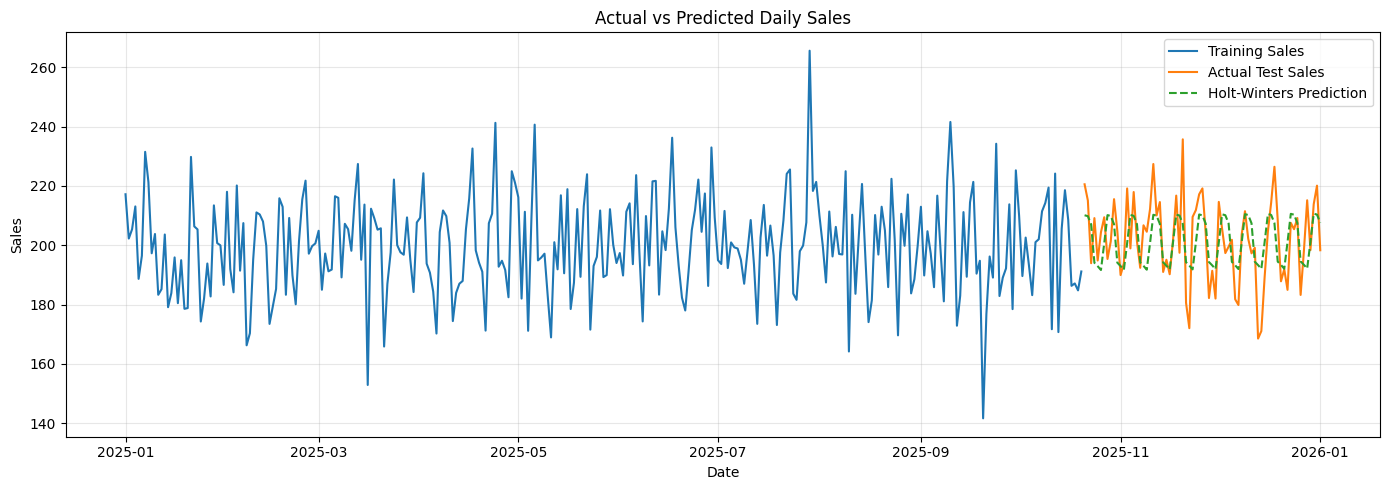

In [44]:

plt.figure(figsize=(14, 5))

plt.plot(
    train.index,
    train,
    label="Training Sales"
)

plt.plot(
    test.index,
    test,
    label="Actual Test Sales"
)

plt.plot(
    test.index,
    test_predictions,
    label="Holt-Winters Prediction",
    linestyle="--"
)

plt.title("Actual vs Predicted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [45]:

final_model = ExponentialSmoothing(
    daily_sales,
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
)

final_fit = final_model.fit(optimized=True)

forecast_days = 30

future_forecast = final_fit.forecast(forecast_days)

# Sales cannot be negative
future_forecast = future_forecast.clip(lower=0)

forecast_df = pd.DataFrame({
    "Date": future_forecast.index,
    "Predicted Sales": future_forecast.values
})

display(forecast_df)


,Date,Predicted Sales
0,2026-01-02,194.867474
1,2026-01-03,192.664853
2,2026-01-04,192.716054
3,2026-01-05,201.959823
4,2026-01-06,210.867362
5,2026-01-07,210.285746
6,2026-01-08,207.985844
7,2026-01-09,194.923411
8,2026-01-10,192.720790
9,2026-01-11,192.771992


In [46]:

output_file = "Holt_Winters_Sales_Forecast.xlsx"

with pd.ExcelWriter(output_file) as writer:
    forecast_df.to_excel(
        writer,
        sheet_name="30_Day_Forecast",
        index=False
    )

    performance.to_excel(
        writer,
        sheet_name="Model_Performance",
        index=False
    )

print("Forecast saved:", output_file)


Forecast saved: Holt_Winters_Sales_Forecast.xlsx


Create trading code dropdown and future date picker

In [58]:

import os
import re
import numpy as np
import pandas as pd
import tensorflow as tf
import ipywidgets as widgets
import matplotlib.pyplot as plt

from IPython.display import display, clear_output
from datetime import date
from sklearn.preprocessing import MinMaxScaler

MODEL_DIR = "DSE_LSTM_Models"
WINDOW = 20

# ============================================================
# 1. EXCLUDE MUTUAL FUNDS AND TREASURY BONDS
# ============================================================

EXCLUDED_CODES = {
    "1JANATAMF", "1STPRIMFMF", "AIBL1STIMF",
    "ATCSLGF", "CAPMBDBLMF", "CAPMIBBLMF",
    "DBH1STMF", "EBL1STMF", "EBLNRBMF",
    "EXIM1STMF", "FBFIF", "IC3RDNRB",
    "ICBAGRANI1", "ICBAMCL2ND", "ICBEPMF1S1",
    "ICBSONALI1", "IFILISLMF1", "LANKABA1MF",
    "LRGLOBMF1", "MBL1STMF", "NCCBLMF1",
    "NLI1STMF", "PHPMF1", "POPULAR1MF",
    "PRIME1ICBA", "RELIANCE1", "SEMLIBBLSF",
    "SEMLLECMF", "TRUSTB1MF", "VAMLBDG1",
    "VAMLRBBF", "VAMLBDMF1"
}

def is_excluded(code):
    code = str(code).strip().upper()
    return (
        code in EXCLUDED_CODES
        or bool(re.fullmatch(r"TB\d+Y\d+", code))
    )

# ============================================================
# 2. PREPARE HISTORICAL DATA
# ============================================================

if "df" not in globals():
    if "df_shares" in globals():
        df = df_shares.copy()
    elif "df_pred" in globals():
        df = df_pred.copy()
    else:
        raise NameError("Historical dataframe not found.")

df_pred = df.copy()

df_pred.columns = (
    df_pred.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

df_pred = df_pred.rename(
    columns={"closep*": "close", "closep": "close"}
)

required = {"trading_code", "date", "close"}
if not required.issubset(df_pred.columns):
    raise ValueError(
        f"Missing historical columns: {required - set(df_pred.columns)}"
    )

df_pred["date"] = pd.to_datetime(
    df_pred["date"], errors="coerce"
)

df_pred["close"] = pd.to_numeric(
    df_pred["close"], errors="coerce"
)

df_pred["trading_code"] = (
    df_pred["trading_code"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_pred = df_pred.dropna(
    subset=["trading_code", "date", "close"]
)

df_pred = df_pred[
    ~df_pred["trading_code"].apply(is_excluded)
].copy()

# ============================================================
# 3. FIND SAVED MODELS
# ============================================================

def model_path(code):
    safe = re.sub(r"[^A-Za-z0-9_-]", "_", code)
    return os.path.join(MODEL_DIR, safe + ".keras")

available_codes = sorted(
    code for code in df_pred["trading_code"].unique()
    if os.path.exists(model_path(code))
)

if not available_codes:
    raise ValueError("No matching saved models found.")

# ============================================================
# 4. LSTM PREDICTION FUNCTION
# ============================================================

def predict_stock_price(trading_code, future_date):

    data = df_pred[
        df_pred["trading_code"] == trading_code
    ].sort_values("date")

    if len(data) < WINDOW:
        raise ValueError(
            f"At least {WINDOW} historical records required."
        )

    last_date = data["date"].iloc[-1].date()
    last_close = float(data["close"].iloc[-1])

    if future_date <= last_date:
        raise ValueError(
            f"Choose a date after {last_date}."
        )

    # Weekdays only; DSE holidays are not accounted for.
    forecast_dates = pd.bdate_range(
        start=pd.Timestamp(last_date) + pd.Timedelta(days=1),
        end=pd.Timestamp(future_date)
    )

    steps = len(forecast_dates)

    if steps == 0:
        raise ValueError("No forecast days in selected period.")

    # WARNING: This scaler must match the one used in training.
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(
        data[["close"]].values
    )

    sequence = scaled[-WINDOW:].reshape(1, WINDOW, 1)

    model = tf.keras.models.load_model(
        model_path(trading_code),
        compile=False
    )

    predictions = []

    for _ in range(steps):
        next_scaled = float(
            model.predict(sequence, verbose=0)[0, 0]
        )

        next_price = float(
            scaler.inverse_transform(
                np.array([[next_scaled]])
            )[0, 0]
        )

        predictions.append(next_price)

        sequence = np.concatenate(
            [
                sequence[:, 1:, :],
                np.array([[[next_scaled]]])
            ],
            axis=1
        )

    return {
        "code": trading_code,
        "last_date": last_date,
        "last_close": last_close,
        "future_date": future_date,
        "predicted_close": predictions[-1],
        "forecast_dates": forecast_dates,
        "forecast_prices": predictions
    }

# ============================================================
# 5. INTERACTIVE USER INTERFACE
# ============================================================

code_dropdown = widgets.Combobox(
    options=available_codes,
    value=(
        "BRACBANK"
        if "BRACBANK" in available_codes
        else available_codes[0]
    ),
    ensure_option=True,
    description="Trading Code:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="420px")
)

date_picker = widgets.DatePicker(
    description="Future Prediction Date:",
    value=None,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="420px")
)

predict_button = widgets.Button(
    description="PREDICT STOCK PRICE",
    button_style="success",
    icon="line-chart",
    layout=widgets.Layout(width="250px")
)

status = widgets.HTML()
output = widgets.Output()

def on_predict_clicked(button):

    with output:
        clear_output(wait=True)

    if date_picker.value is None:
        status.value = (
            "<span style='color:red'>"
            "Please select a future date."
            "</span>"
        )
        return

    predict_button.disabled = True
    predict_button.description = "PREDICTING..."
    predict_button.icon = "spinner"

    status.value = (
        "<b style='color:#0E7C86'>"
        "⏳ Loading LSTM model and forecasting..."
        "</b>"
    )

    try:
        result = predict_stock_price(
            code_dropdown.value,
            date_picker.value
        )

        predicted = result["predicted_close"]
        last_close = result["last_close"]

        change = predicted - last_close
        change_pct = (
            change / last_close * 100
            if last_close else np.nan
        )

        with output:
            print("=" * 55)
            print("DSE LSTM STOCK PRICE FORECAST")
            print("=" * 55)
            print("Trading Code:", result["code"])
            print("Last Actual Date:", result["last_date"])
            print(f"Last Actual Close: BDT {last_close:.2f}")
            print("Prediction Date:", result["future_date"])
            print(f"Predicted Close: BDT {predicted:.2f}")
            print(f"Estimated Change: BDT {change:+.2f}")
            print(f"Estimated Return: {change_pct:+.2f}%")

            plt.figure(figsize=(12, 5))
            plt.plot(
                result["forecast_dates"],
                result["forecast_prices"],
                color="#0E7C86",
                label="LSTM Forecast"
            )
            plt.axhline(
                last_close,
                color="orange",
                linestyle="--",
                label="Last Actual Close"
            )
            plt.title(f"{result['code']} — Forecast")
            plt.xlabel("Date")
            plt.ylabel("Price (BDT)")
            plt.legend()
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()

        status.value = (
            "<b style='color:green'>"
            "✓ Prediction completed."
            "</b>"
        )

    except Exception as e:
        status.value = (
            f"<b style='color:red'>Prediction error: {e}</b>"
        )

    finally:
        predict_button.disabled = False
        predict_button.description = "PREDICT STOCK PRICE"
        predict_button.icon = "line-chart"

predict_button.on_click(on_predict_clicked)

display(
    widgets.VBox([
        widgets.HTML(
            "<h3>DSE LSTM Stock Price Forecast</h3>"
        ),
        code_dropdown,
        date_picker,
        predict_button,
        status,
        output
    ])
)


In [59]:

def predict_stock_price(code, future_date):

    company = (
        df_pred[df_pred["trading_code"] == code]
        .sort_values("date")
        .drop_duplicates("date", keep="last")
    )

    if len(company) < WINDOW:
        raise ValueError("Insufficient historical prices.")

    last_actual_date = company["date"].iloc[-1]
    last_actual_close = float(company["close"].iloc[-1])

    target_date = pd.Timestamp(future_date)

    if target_date <= last_actual_date:
        raise ValueError(
            "Prediction date must be after last actual date."
        )

    # DSE normally trades Sunday to Thursday
    # This excludes Friday and Saturday but not exchange holidays.
    future_sessions = pd.date_range(
        start=last_actual_date + pd.Timedelta(days=1),
        end=target_date,
        freq="D"
    )

    future_sessions = future_sessions[
        future_sessions.dayofweek.isin([6, 0, 1, 2, 3])
    ]

    steps = len(future_sessions)

    if steps == 0:
        raise ValueError(
            "No estimated trading sessions before selected date."
        )

    model_path = os.path.join(
        MODEL_DIR,
        re.sub(r"[^A-Za-z0-9_-]", "_", code) + ".keras"
    )

    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    # IMPORTANT:
    # Ideally load the original scaler saved during training.
    # This reconstruction is only valid if training used
    # the same fitted scaler parameters.
    prices = company["close"].values.reshape(-1, 1)

    scaler = MinMaxScaler()
    scaler.fit(prices)

    scaled_prices = scaler.transform(prices).flatten()

    current_window = scaled_prices[-WINDOW:].copy()

    predictions = []

    for step in range(steps):

        X_input = current_window.reshape(
            1, WINDOW, 1
        )

        predicted_scaled = float(
            model.predict(X_input, verbose=0)[0, 0]
        )

        # Update window with prediction
        current_window = np.append(
            current_window[1:],
            predicted_scaled
        )

        predicted_close = float(
            scaler.inverse_transform(
                [[predicted_scaled]]
            )[0, 0]
        )

        predictions.append(predicted_close)

    result = pd.DataFrame({
        "Date": future_sessions,
        "Predicted Close (BDT)": predictions
    })

    return {
        "code": code,
        "last_date": last_actual_date,
        "last_close": last_actual_close,
        "target_date": target_date,
        "forecast_steps": steps,
        "predicted_close": predictions[-1],
        "forecast_table": result
    }


In [60]:
def on_predict_clicked(button):
    with output:
        clear_output(wait=True)
        print("⏳ Calculating predictions... Please wait... (this can take a few seconds)")

        code = code_dropdown.value
        future_date = date_picker.value

        if future_date is None:
            clear_output(wait=True)
            print("Please select a future date.")
            return

        try:
            result = predict_stock_price(
                code,
                future_date
            )

            # Done calculating; clear the loading indicator
            clear_output(wait=True)

            predicted = result["predicted_close"]
            actual = result["last_close"]

            difference = predicted - actual
            estimated_return = (
                difference / actual * 100
                if actual != 0 else np.nan
            )

            print("=" * 55)
            print("DSE STOCK PRICE PREDICTION")
            print("=" * 55)

            print("Trading Code:", result["code"])
            print("Last Actual Date:", result["last_date"].date())
            print("Last Actual Close: BDT", round(actual, 2))
            print("Prediction Date:", result["target_date"].date())
            print("Forecast Steps:", result["forecast_steps"])

            print("-" * 55)
            print("Predicted Close: BDT", round(predicted, 2))
            print("Price Difference: BDT", round(difference, 2))
            print("Estimated Return:", round(estimated_return, 2), "%")

            print("\nRecent forecast:")
            display(result["forecast_table"].tail(10))

            import matplotlib.pyplot as plt

            forecast = result["forecast_table"]

            plt.figure(figsize=(12, 5))
            plt.plot(
                forecast["Date"],
                forecast["Predicted Close (BDT)"],
                label="Predicted Price"
            )

            plt.axhline(
                actual,
                linestyle="--",
                label="Last Actual Close"
            )

            plt.title(f"{code} — Future Stock Price Forecast")
            plt.xlabel("Date")
            plt.ylabel("Price (BDT)")
            plt.legend()
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()

            if predicted < 0:
                print(
                    "\nWARNING: Negative predicted price. "
                    "This is an invalid stock price and indicates "
                    "unstable recursive forecasting."
                )

            if result["forecast_steps"] > 30:
                print(
                    "\nWARNING: Long-horizon recursive predictions "
                    "can accumulate substantial errors."
                )

        except Exception as e:
            clear_output(wait=True)
            print("Prediction error:", str(e))

predict_button.on_click(on_predict_clicked)
print("Prediction interface ready with active prediction status indicator.")

Prediction interface ready with active prediction status indicator.


In [61]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output

# Remove previously attached handlers when rerunning this cell
predict_button._click_handlers.callbacks.clear()

def on_predict_clicked(button):

    code = code_dropdown.value
    future_date = date_picker.value

    if future_date is None:
        with output:
            clear_output(wait=True)
            print("Please select a future prediction date.")
        return

    predict_button.disabled = True
    predict_button.description = "PREDICTING..."
    predict_button.icon = "spinner"

    with output:
        clear_output(wait=True)
        display(
            widgets.HTML(
                "<h4 style='color:#0E7C86'>"
                "⏳ Loading model and calculating prediction..."
                "</h4>"
            )
        )

    try:
        result = predict_stock_price(
            code,
            future_date
        )

        predicted = float(result["predicted_close"])
        actual = float(result["last_close"])

        difference = predicted - actual

        estimated_return = (
            difference / actual * 100
            if actual != 0 else np.nan
        )

        # Handle date or pandas Timestamp
        last_actual_date = pd.Timestamp(
            result["last_date"]
        ).date()

        target_date = pd.Timestamp(
            result.get("target_date", future_date)
        ).date()

        forecast = result.get("forecast_table")

        with output:
            clear_output(wait=True)

            print("=" * 55)
            print("DSE STOCK PRICE PREDICTION")
            print("=" * 55)

            print("Trading Code:", code)
            print("Last Actual Date:", last_actual_date)
            print(f"Last Actual Close: BDT {actual:.2f}")
            print("Prediction Date:", target_date)
            print(
                "Forecast Steps:",
                result.get("forecast_steps", "Not available")
            )

            print("-" * 55)
            print(f"Predicted Close: BDT {predicted:.2f}")
            print(f"Price Difference: BDT {difference:+.2f}")
            print(f"Estimated Return: {estimated_return:+.2f}%")

            if isinstance(forecast, pd.DataFrame) and not forecast.empty:

                print("\nRecent Forecast:")
                display(forecast.tail(10))

                if {
                    "Date",
                    "Predicted Close (BDT)"
                }.issubset(forecast.columns):

                    plt.figure(figsize=(12, 5))

                    plt.plot(
                        forecast["Date"],
                        forecast["Predicted Close (BDT)"],
                        color="#0E7C86",
                        linewidth=2,
                        label="Predicted Closing Price"
                    )

                    plt.axhline(
                        actual,
                        color="orange",
                        linestyle="--",
                        label="Last Actual Close"
                    )

                    plt.title(
                        f"{code} — Future Stock Price Forecast"
                    )
                    plt.xlabel("Date")
                    plt.ylabel("Price (BDT)")
                    plt.legend()
                    plt.grid(alpha=0.3)
                    plt.tight_layout()
                    plt.show()

            if predicted < 0:
                print(
                    "\nWARNING: Negative stock price forecast. "
                    "The model output is not economically valid."
                )

            steps = result.get("forecast_steps", 0)

            if isinstance(steps, (int, float)) and steps > 30:
                print(
                    "\nWARNING: Long-horizon recursive forecasts "
                    "may accumulate substantial prediction errors."
                )

    except Exception as e:
        with output:
            clear_output(wait=True)
            print("Prediction error:", str(e))

    finally:
        predict_button.disabled = False
        predict_button.description = "PREDICT STOCK PRICE"
        predict_button.icon = "line-chart"

predict_button.on_click(on_predict_clicked)

print("Prediction button connected successfully.")


Prediction button connected successfully.


In [62]:

display(
    widgets.VBox([
        widgets.HTML(
            "<h2 style='color:#0E7C86'>"
            "DSE LSTM Stock Price Predictor"
            "</h2>"
        ),
        code_dropdown,
        date_picker,
        predict_button,
        output
    ])
)


In [63]:

import os
import re
import ipywidgets as widgets

MODEL_DIR = "DSE_LSTM_Models"

EXCLUDED_CODES = {
    "1JANATAMF", "1STPRIMFMF", "AIBL1STIMF",
    "ATCSLGF", "CAPMBDBLMF", "CAPMIBBLMF",
    "DBH1STMF", "EBL1STMF", "EBLNRBMF",
    "EXIM1STMF", "FBFIF", "IC3RDNRB",
    "ICBAGRANI1", "ICBAMCL2ND", "ICBEPMF1S1",
    "ICBSONALI1", "IFILISLMF1", "LANKABA1MF",
    "LRGLOBMF1", "MBL1STMF", "NCCBLMF1",
    "NLI1STMF", "PHPMF1", "POPULAR1MF",
    "PRIME1ICBA", "RELIANCE1", "SEMLIBBLSF",
    "SEMLLECMF", "TRUSTB1MF", "VAMLBDG1",
    "VAMLRBBF", "VAMLBDMF1"
}

def is_non_share(code):
    code = str(code).strip().upper()

    return (
        code in EXCLUDED_CODES
        or bool(re.fullmatch(r"TB\d+Y\d+", code))
        or "BOND" in code
        or "SUKUK" in code
        or "DEB" in code
    )

# Discover saved model files
saved_codes = {
    filename[:-6].upper()
    for filename in os.listdir(MODEL_DIR)
    if filename.lower().endswith(".keras")
}

# Use codes present in your historical dataframe
data_codes = {
    str(code).strip().upper()
    for code in df_pred["trading_code"].dropna().unique()
}

# Only codes with both data and saved models
active_share_codes = sorted(
    code for code in saved_codes.intersection(data_codes)
    if not is_non_share(code)
)

print("Saved models:", len(saved_codes))
print("Active share models:", len(active_share_codes))
print("First 30 active codes:", active_share_codes[:30])

if not active_share_codes:
    raise ValueError(
        "No share codes have both a saved model and historical data."
    )


Saved models: 367
Active share models: 362
First 30 active codes: ['AAMRANET', 'AAMRATECH', 'ABBANK', 'ACFL', 'ACI', 'ACIFORMULA', 'ACMELAB', 'ACMEPL', 'ACTIVEFINE', 'ADNTEL', 'ADVENT', 'AFCAGRO', 'AFTABAUTO', 'AGNISYSL', 'AGRANINS', 'AIL', 'AL-HAJTEX', 'ALARABANK', 'ALIF', 'ALLTEX', 'AMANFEED', 'AMBEEPHA', 'ANLIMAYARN', 'ANWARGALV', 'AOL', 'APEXFOODS', 'APEXFOOT', 'APEXSPINN', 'APEXTANRY', 'APOLOISPAT']


In [66]:
# Update the existing dropdown
code_dropdown.options = active_share_codes

# Set BRACBANK as default if available
code_dropdown.value = (
    "BRACBANK"
    if "BRACBANK" in active_share_codes
    else active_share_codes[0]
)

print(
    f"Dropdown updated with {len(active_share_codes)} trained share codes.\n"
)
print("All active share codes:")
import pprint
pprint.pprint(active_share_codes, compact=True, width=80)

Dropdown updated with 362 trained share codes.

All active share codes:
['AAMRANET', 'AAMRATECH', 'ABBANK', 'ACFL', 'ACI', 'ACIFORMULA', 'ACMELAB',
 'ACMEPL', 'ACTIVEFINE', 'ADNTEL', 'ADVENT', 'AFCAGRO', 'AFTABAUTO', 'AGNISYSL',
 'AGRANINS', 'AIL', 'AL-HAJTEX', 'ALARABANK', 'ALIF', 'ALLTEX', 'AMANFEED',
 'AMBEEPHA', 'ANLIMAYARN', 'ANWARGALV', 'AOL', 'APEXFOODS', 'APEXFOOT',
 'APEXSPINN', 'APEXTANRY', 'APOLOISPAT', 'ARAMIT', 'ARAMITCEM', 'ARGONDENIM',
 'ASIAINS', 'ASIAPACINS', 'ASIATICLAB', 'ATLASBANG', 'AZIZPIPES', 'BANGAS',
 'BANKASI1PB', 'BANKASIA', 'BARKAPOWER', 'BATASHOE', 'BATBC', 'BAYLEASING',
 'BBS', 'BBSCABLES', 'BDAUTOCA', 'BDCOM', 'BDFINANCE', 'BDLAMPS', 'BDSERVICE',
 'BDTHAI', 'BDTHAIFOOD', 'BDWELDING', 'BEACHHATCH', 'BEACONPHAR', 'BENGALWTL',
 'BERGERPBL', 'BESTHLDNG', 'BEXIMCO', 'BGIC', 'BIFC', 'BNICL', 'BPML', 'BPPL',
 'BRACBANK', 'BSC', 'BSCPLC', 'BSRMLTD', 'BSRMSTEEL', 'BXPHARMA', 'CAPITECGBF',
 'CENTRALINS', 'CENTRALPHL', 'CITYBANK', 'CITYGENINS', 'CLICL', 'CNATEX',
 '

In [67]:

from IPython.display import display

display(
    widgets.VBox([
        widgets.HTML(
            "<h2 style='color:#0E7C86'>"
            "DSE LSTM Stock Price Predictor"
            "</h2>"
        ),
        code_dropdown,
        date_picker,
        predict_button,
        output
    ])
)


In [70]:
import pandas as pd
import numpy as np
from datetime import date

# Define the target prediction date
target_prediction_date = date(2027, 1, 14)
all_predictions = []

print(f"Starting optimized batch forecasting for {len(active_share_codes)} active share codes up to {target_prediction_date}...")

for idx, code in enumerate(active_share_codes, 1):
    try:
        # Ensure we reuse pre-loaded models from memory if available to prevent file I/O overhead
        if code in stock_models:
            # Inline fast prediction using pre-loaded model & scaler
            company = df_pred[df_pred["trading_code"] == code].sort_values("date").drop_duplicates("date", keep="last")
            if len(company) < WINDOW:
                continue

            last_actual_date = company["date"].iloc[-1]
            last_actual_close = float(company["close"].iloc[-1])
            target_date = pd.Timestamp(target_prediction_date)

            future_sessions = pd.date_range(start=last_actual_date + pd.Timedelta(days=1), end=target_date, freq="D")
            future_sessions = future_sessions[future_sessions.dayofweek.isin([6, 0, 1, 2, 3])]
            steps = len(future_sessions)
            if steps == 0:
                continue

            model = stock_models[code]
            prices = company["close"].values.reshape(-1, 1)
            scaler = stock_scalers[code]
            scaled_prices = scaler.transform(prices).flatten()
            current_window = scaled_prices[-WINDOW:].copy()

            # Fast recursive prediction loop
            for step in range(steps):
                X_input = current_window.reshape(1, WINDOW, 1)
                predicted_scaled = float(model.predict(X_input, verbose=0)[0, 0])
                current_window = np.append(current_window[1:], predicted_scaled)

            predicted_close = float(scaler.inverse_transform([[predicted_scaled]])[0, 0])

            all_predictions.append({
                'TRADING CODE': code,
                'Last Actual Date': last_actual_date.date(),
                'Last Actual Close (BDT)': last_actual_close,
                'Target Date': target_date.date(),
                'Forecast Steps': steps,
                'Predicted Close (BDT)': predicted_close,
                'Price Difference (BDT)': predicted_close - last_actual_close,
                'Estimated Return (%)': ((predicted_close - last_actual_close) / last_actual_close * 100) if last_actual_close != 0 else 0
            })

        if idx % 50 == 0 or idx == len(active_share_codes):
            print(f"Processed {idx}/{len(active_share_codes)} codes...")
    except Exception as e:
        continue

# Convert to DataFrame and save to CSV
batch_forecast_df = pd.DataFrame(all_predictions)
batch_forecast_df.to_csv('DSE_All_Shares_LSTM_Predictions.csv', index=False)
print(f"\nConsolidated predictions saved to 'DSE_All_Shares_LSTM_Predictions.csv'!")
display(batch_forecast_df.head(10))

Starting optimized batch forecasting for 362 active share codes up to 2027-01-14...


KeyboardInterrupt: 

In [69]:

import pandas as pd
import numpy as np
import ipywidgets as widgets
import matplotlib.pyplot as plt

from datetime import date, timedelta
from IPython.display import display, clear_output, FileLink

# Ensure required objects exist
if "active_share_codes" not in globals() or not active_share_codes:
    raise ValueError("Run the active_share_codes preparation cell first.")

if "predict_stock_price" not in globals():
    raise NameError("Run the predict_stock_price function cell first.")

# Trading code selection
manual_code = widgets.Combobox(
    options=sorted(active_share_codes),
    value=(
        "BRACBANK"
        if "BRACBANK" in active_share_codes
        else sorted(active_share_codes)[0]
    ),
    ensure_option=True,
    description="Trading Code:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="430px")
)

# Manual date selection
manual_date = widgets.DatePicker(
    description="Future Prediction Date:",
    value=date.today() + timedelta(days=30),
    style={"description_width": "initial"},
    layout=widgets.Layout(width="430px")
)

predict_btn = widgets.Button(
    description="PREDICT CLOSING PRICE",
    button_style="success",
    icon="line-chart",
    layout=widgets.Layout(width="270px")
)

status = widgets.HTML()
result_output = widgets.Output()

def run_manual_prediction(button):

    code = manual_code.value.strip().upper()
    target_date = manual_date.value

    with result_output:
        clear_output(wait=True)

    if code not in active_share_codes:
        status.value = "<b style='color:red'>Invalid trading code.</b>"
        return

    if target_date is None:
        status.value = "<b style='color:red'>Select a future date.</b>"
        return

    predict_btn.disabled = True
    predict_btn.description = "PREDICTING..."
    predict_btn.icon = "spinner"

    status.value = (
        "<b style='color:#0E7C86'>"
        "⏳ Loading LSTM model and forecasting..."
        "</b>"
    )

    try:
        res = predict_stock_price(code, target_date)

        actual = float(res["last_close"])
        predicted = float(res["predicted_close"])
        difference = predicted - actual

        estimated_return = (
            difference / actual * 100
            if actual != 0 else np.nan
        )

        result_df = pd.DataFrame([{
            "Trading Code": code,
            "Last Actual Date": pd.Timestamp(res["last_date"]).date(),
            "Last Actual Close (BDT)": round(actual, 2),
            "Prediction Date": pd.Timestamp(
                res.get("target_date", target_date)
            ).date(),
            "Forecast Steps": res.get("forecast_steps", np.nan),
            "Predicted Close (BDT)": round(predicted, 2),
            "Price Difference (BDT)": round(difference, 2),
            "Estimated Return (%)": round(estimated_return, 2)
        }])

        filename = f"DSE_{code}_LSTM_Prediction.csv"
        result_df.to_csv(filename, index=False)

        with result_output:
            print("=" * 55)
            print("DSE LSTM STOCK PRICE PREDICTION")
            print("=" * 55)
            display(result_df)

            forecast = res.get("forecast_table")

            if isinstance(forecast, pd.DataFrame) and not forecast.empty:
                display(forecast.tail(10))

                if {
                    "Date", "Predicted Close (BDT)"
                }.issubset(forecast.columns):

                    plt.figure(figsize=(12, 5))
                    plt.plot(
                        forecast["Date"],
                        forecast["Predicted Close (BDT)"],
                        color="#0E7C86",
                        label="Predicted Closing Price"
                    )
                    plt.axhline(
                        actual,
                        color="orange",
                        linestyle="--",
                        label="Last Actual Close"
                    )
                    plt.title(f"{code} — LSTM Forecast")
                    plt.xlabel("Date")
                    plt.ylabel("Price (BDT)")
                    plt.legend()
                    plt.grid(alpha=0.3)
                    plt.tight_layout()
                    plt.show()

            display(FileLink(filename))

            if predicted < 0:
                print(
                    "WARNING: Negative predicted price. "
                    "Forecast is not economically valid."
                )

            if res.get("forecast_steps", 0) > 30:
                print(
                    "WARNING: Long-horizon recursive forecasts "
                    "can accumulate substantial errors."
                )

        status.value = (
            "<b style='color:green'>"
            "✓ Prediction completed successfully."
            "</b>"
        )

    except Exception as e:
        status.value = (
            f"<b style='color:red'>Prediction error: {e}</b>"
        )

    finally:
        predict_btn.disabled = False
        predict_btn.description = "PREDICT CLOSING PRICE"
        predict_btn.icon = "line-chart"

predict_btn.on_click(run_manual_prediction)

display(
    widgets.VBox([
        widgets.HTML(
            "<h2 style='color:#0E7C86'>"
            "DSE LSTM Stock Price Predictor</h2>"
        ),
        manual_code,
        manual_date,
        predict_btn,
        status,
        result_output
    ])
)


In [72]:
import os
import re
import ipywidgets as widgets

# Define the missing helper function to check if a model has been trained/saved
def has_trained_model(code):
    # Check if pre-loaded in memory first
    if "stock_models" in globals() and code in stock_models:
        return True
    # Otherwise check if a keras file exists in the directory
    safe_name = re.sub(r"[^A-Za-z0-9_-]", "_", code) + ".keras"
    return os.path.exists(os.path.join(MODEL_DIR, safe_name))

# Fallback if all_share_codes is empty or undefined
if "all_share_codes" not in globals() or not all_share_codes:
    if "active_share_codes" in globals():
        all_share_codes = active_share_codes
    else:
        raise ValueError("No share trading codes found in memory.")

dropdown_options = [
    (
        f"{code} — {'Ready' if has_trained_model(code) else 'Not trained'}",
        code
    )
    for code in all_share_codes
]

manual_code = widgets.Dropdown(
    options=dropdown_options,
    value=all_share_codes[0],
    description="Trading Code:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

display(manual_code)

Dropdown(description='Trading Code:', layout=Layout(width='450px'), options=(('AAMRANET — Ready', 'AAMRANET'),…

In [73]:

if not all_share_codes:
    raise ValueError("No share trading codes found in df_pred.")

dropdown_options = [
    (
        f"{code} — {'Ready' if has_trained_model(code) else 'Not trained'}",
        code
    )
    for code in all_share_codes
]

manual_code = widgets.Dropdown(
    options=dropdown_options,
    value=all_share_codes[0],
    description="Trading Code:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="450px")
)

display(manual_code)


Dropdown(description='Trading Code:', layout=Layout(width='450px'), options=(('AAMRANET — Ready', 'AAMRANET'),…

In [75]:
def validate_trading_code(code):
    if code not in active_share_codes:
        status.value = "<b style='color:red'>Invalid trading code.</b>"
        return False
    return True

In [77]:
def check_model_status(code):
    if code not in all_share_codes:
        status.value = "<b style='color:red'>Invalid trading code.</b>"
        return False

    if not has_trained_model(code):
        status.value = (
            f"<b style='color:red'>"
            f"No trained LSTM model available for {code}. "
            f"Please train this share first."
            f"</b>"
        )
        return False
    return True

In [78]:
display(
    widgets.VBox([
        widgets.HTML("<h2>DSE LSTM Stock Price Predictor</h2>"),
        manual_code,
        manual_date,
        predict_btn,
        status,
        result_output
    ])
)

## Part 4 — Deploying a Prediction Pipeline

A trained model is only useful if it can be reused without retraining. We save the entire preprocessing + model pipeline as a single file, then show how another program (e.g. a web service) would load it and make predictions on brand-new data.

## Discussion prompts for class

- Why must the stock and sales train/test splits be done **by date**, rather than a random shuffle? What would go wrong if you shuffled first?
- The LSTM only used closing price. What other features (volume, moving averages, other tickers) might improve it, and why?
- For the waiter tips model, is R² alone enough to choose a "best" model? What would you also want to check (e.g. overfitting, interpretability, prediction speed)?
- Why does a saved pipeline (preprocessing + model together) matter for deployment, compared to saving only the trained model?

These are exactly the kinds of questions your **Evaluation and Model Comparison** and **Result Interpretation and Report** deliverables ask you to answer.